# 01 – Khám phá dữ liệu: nhóm cột số (Chỉ số thi đấu · Kinh tế · Sát thương · Trang bị)
Phần của mục **3.2 Data exploration** (Overview, Numerical columns, Relationships) cho nhóm cột số.

## 0. Cấu hình & nạp dữ liệu
`DEEP_COLS` là các cột **đi sâu** (có biểu đồ riêng). Khi nhóm chốt câu hỏi, sửa danh sách này; các cột còn lại chỉ được tóm tắt bằng bảng.

In [14]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 9})
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

FILENAME = "League of Legends Ranked Match Data  Season 15 (EUN).csv"


def find_data_file(filename):
    roots = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
    sub_dirs = ["data/raw", "Data/raw", "data", "Data", "raw", ""]
    
    # 1. Tìm đúng tên file chỉ định ở các vị trí thường gặp
    for r in roots:
        for sub in sub_dirs:
            p = (r / sub / filename).resolve()
            if p.is_file():
                return p
                
    # 2. Quét mở rộng nếu tên file có sai lệch nhẹ
    for r in roots[:2]:
        for pattern in ["**/data/raw/*.csv", "**/data/*.csv", "*.csv"]:
            for hit in r.glob(pattern):
                if "league" in hit.name.lower() and "ranked" in hit.name.lower():
                    return hit.resolve()
                    
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {filename}. Hãy kiểm tra lại thư mục data/raw.")


DATA_PATH = find_data_file(FILENAME)
print("Đọc dữ liệu từ:", DATA_PATH)

raw = pd.read_csv(DATA_PATH)
df = raw.copy()
df["duration_min"] = df["duration"] / 60  # duration gốc tính bằng GIÂY

# ---- Nhóm cột phụ trách ----
PERF = ["kills", "deaths", "assists", "kda_ratio", "kill_participation", "vision_score"]
ECON = ["gold_earned", "gold_spent", "gold_per_min"]
DMG = ["damage_dealt", "damage_per_min", "damage_to_champ", "damage_champ_per_min", "damage_taken"]
NUM_MAIN = PERF + ECON + DMG
ITEM_COLS = [f"item{i}" for i in range(7)]  # item0-5: ô trang bị, item6: trinket
ITEM_SLOTS = ITEM_COLS[:6]
FINAL_COLS = [c for c in df.columns if c.startswith("final_")]
ROLE_ORDER = ["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "SUPPORT"]
EMPTY = "Item_0"  # placeholder của ô trống (xem mục 7)
EARLY_SEC = 15 * 60  # ngưỡng remake / đầu hàng sớm: 15 phút

# ---- Cột đi sâu: SỬA khi nhóm chốt câu hỏi ----
DEEP_COLS = ["kda_ratio", "vision_score", "gold_per_min", "damage_champ_per_min", "damage_taken", "kill_participation"]

print(f"Đọc thành công từ: {DATA_PATH}\nShape: {df.shape}")

Đọc dữ liệu từ: D:\Tai\KHDL\OpenthedoorForDataScience\data\raw\League of Legends Ranked Match Data  Season 15 (EUN).csv
Đọc thành công từ: D:\Tai\KHDL\OpenthedoorForDataScience\data\raw\League of Legends Ranked Match Data  Season 15 (EUN).csv
Shape: (68300, 70)


## 3.2 Data exploration – nhóm cột số

### A. Overview
Một dòng = **một người chơi trong một trận** (10 dòng/trận). Các cột `duration`, `team_*` lặp lại trên 10 dòng cùng trận, nên các phép đếm theo trận phải gộp theo `game_id`.

In [15]:
print(f"Số dòng: {len(df):,} | Số cột: {df.shape[1]} | Số trận: {df.game_id.nunique():,}")
print("Người chơi / trận:", df.groupby("game_id").size().value_counts().to_dict())
print("Dòng trùng hoàn toàn:", df.duplicated().sum(), "| trùng (game_id, participant_id):", df.duplicated(["game_id", "participant_id"]).sum())
print("Dòng rỗng hoàn toàn:", int(df.isna().all(axis=1).sum()))

dictionary = pd.DataFrame([
    ("kills / deaths / assists", "Số lần hạ gục / bị hạ gục / hỗ trợ", "int"),
    ("kda_ratio", "(kills+assists)/deaths; nếu deaths=0 thì = kills+assists", "float"),
    ("kill_participation", "(kills+assists)/team_champKills, trong [0,1]", "float"),
    ("vision_score", "Điểm tầm nhìn (đặt/phá mắt)", "int"),
    ("gold_earned / gold_spent", "Vàng kiếm được / đã tiêu", "int"),
    ("gold_per_min", "gold_earned / số phút của trận", "float"),
    ("damage_dealt / damage_per_min", "Tổng sát thương gây ra (≥ damage_to_champ) và trên mỗi phút", "int / float"),
    ("damage_to_champ / damage_champ_per_min", "Sát thương lên tướng đối phương và trên mỗi phút", "int / float"),
    ("damage_taken", "Sát thương phải nhận", "int"),
    ("item0–item5", "Tên trang bị ở 6 ô; 'Item_0' = ô trống", "str"),
    ("item6", "Trinket (đồ tầm nhìn)", "str"),
    ("final_*", "Chỉ số tướng tại thời điểm kết thúc (AP, AD, giáp, máu…)", "int"),
], columns=["cột", "ý nghĩa", "kiểu"])
display(dictionary)

print("Missing trong nhóm cột phụ trách:", int(df[NUM_MAIN + ITEM_COLS + FINAL_COLS].isna().sum().sum()))
const_cols = [c for c in NUM_MAIN + FINAL_COLS if df[c].nunique() == 1]
print("Cột hằng số (nên bỏ):", const_cols)

Số dòng: 68,300 | Số cột: 70 | Số trận: 6,830
Người chơi / trận: {10: 6830}
Dòng trùng hoàn toàn: 0 | trùng (game_id, participant_id): 0
Dòng rỗng hoàn toàn: 0


,cột,ý nghĩa,kiểu
0,kills / deaths / assists,Số lần hạ gục / bị hạ gục / hỗ trợ,int
1,kda_ratio,(kills+assists)/deaths; nếu deaths=0 thì = kil...,float
2,kill_participation,"(kills+assists)/team_champKills, trong [0,1]",float
3,vision_score,Điểm tầm nhìn (đặt/phá mắt),int
4,gold_earned / gold_spent,Vàng kiếm được / đã tiêu,int
5,gold_per_min,gold_earned / số phút của trận,float
6,damage_dealt / damage_per_min,Tổng sát thương gây ra (≥ damage_to_champ) và ...,int / float
7,damage_to_champ / damage_champ_per_min,Sát thương lên tướng đối phương và trên mỗi phút,int / float
8,damage_taken,Sát thương phải nhận,int
9,item0–item5,Tên trang bị ở 6 ô; 'Item_0' = ô trống,str


Missing trong nhóm cột phụ trách: 0
Cột hằng số (nên bỏ): ['final_abilityHaste']


### B. Numerical columns
#### B1. Bảng tóm tắt cho **tất cả** cột số
Mean/median/IQR cho biết tâm và độ phân tán; `skew` (độ lệch) và `kurt` (độ nhọn) cho biết hình dạng; `mean_vs_median_%` là cách đọc nhanh độ lệch.

In [16]:
def describe_shape(data, cols):
    rows = []
    for c in cols:
        s = data[c].dropna()
        q1, med, q3 = s.quantile([0.25, 0.5, 0.75])
        rows.append({
            "column": c, "mean": s.mean(), "median": med, "std": s.std(),
            "min": s.min(), "q1": q1, "q3": q3, "max": s.max(), "IQR": q3 - q1,
            "skew": s.skew(), "kurt": s.kurt(),
            "mean_vs_median_%": (s.mean() - med) / med * 100 if med != 0 else np.nan,
            "zero_%": (s == 0).mean() * 100,
        })
    out = pd.DataFrame(rows).set_index("column")
    out["skew_level"] = pd.cut(out["skew"].abs(), [-np.inf, 0.5, 1, np.inf], labels=["gần đối xứng", "lệch vừa", "lệch mạnh"])
    return out


summary = describe_shape(df, NUM_MAIN)
display(summary)

,mean,median,std,min,q1,q3,max,IQR,skew,kurt,mean_vs_median_%,zero_%,skew_level
column,,,,,,,,,,,,,
kills,6.283,5.000,4.704,0.000,3.000,9.000,43.000,6.000,1.038,1.266,25.669,5.710,lệch mạnh
deaths,6.303,6.000,3.281,0.000,4.000,8.000,23.000,4.000,0.387,-0.012,5.051,2.092,gần đối xứng
assists,8.467,7.000,6.124,0.000,4.000,11.000,53.000,7.000,1.244,1.981,20.960,2.767,lệch mạnh
kda_ratio,3.420,2.300,3.673,0.000,1.333,4.000,44.000,2.667,3.120,13.191,48.710,0.575,lệch mạnh
kill_participation,0.462,0.465,0.155,0.000,0.357,0.568,1.000,0.210,-0.071,0.034,-0.580,0.575,gần đối xứng
vision_score,26.487,19.000,21.379,0.000,13.000,30.000,191.000,17.000,1.934,4.021,39.407,0.176,lệch mạnh
gold_earned,"11,576.253","11,420.500","3,568.599","1,111.000","9,089.000","13,861.000","30,549.000","4,772.000",0.305,0.208,1.364,0.000,gần đối xứng
gold_spent,"10,686.690","10,575.000","3,447.169",450.000,"8,308.000","12,825.000","44,987.000","4,517.000",0.396,0.881,1.056,0.000,gần đối xứng
gold_per_min,388.964,387.591,80.305,139.788,331.502,442.571,858.981,111.069,0.243,-0.053,0.354,0.000,gần đối xứng


#### B2. Đi sâu vào `DEEP_COLS`
Mỗi cột có histogram (cắt ở phân vị 99.5% để thấy thân phân phối; đường đỏ = mean, xanh = median) và boxplot (toàn bộ dữ liệu).

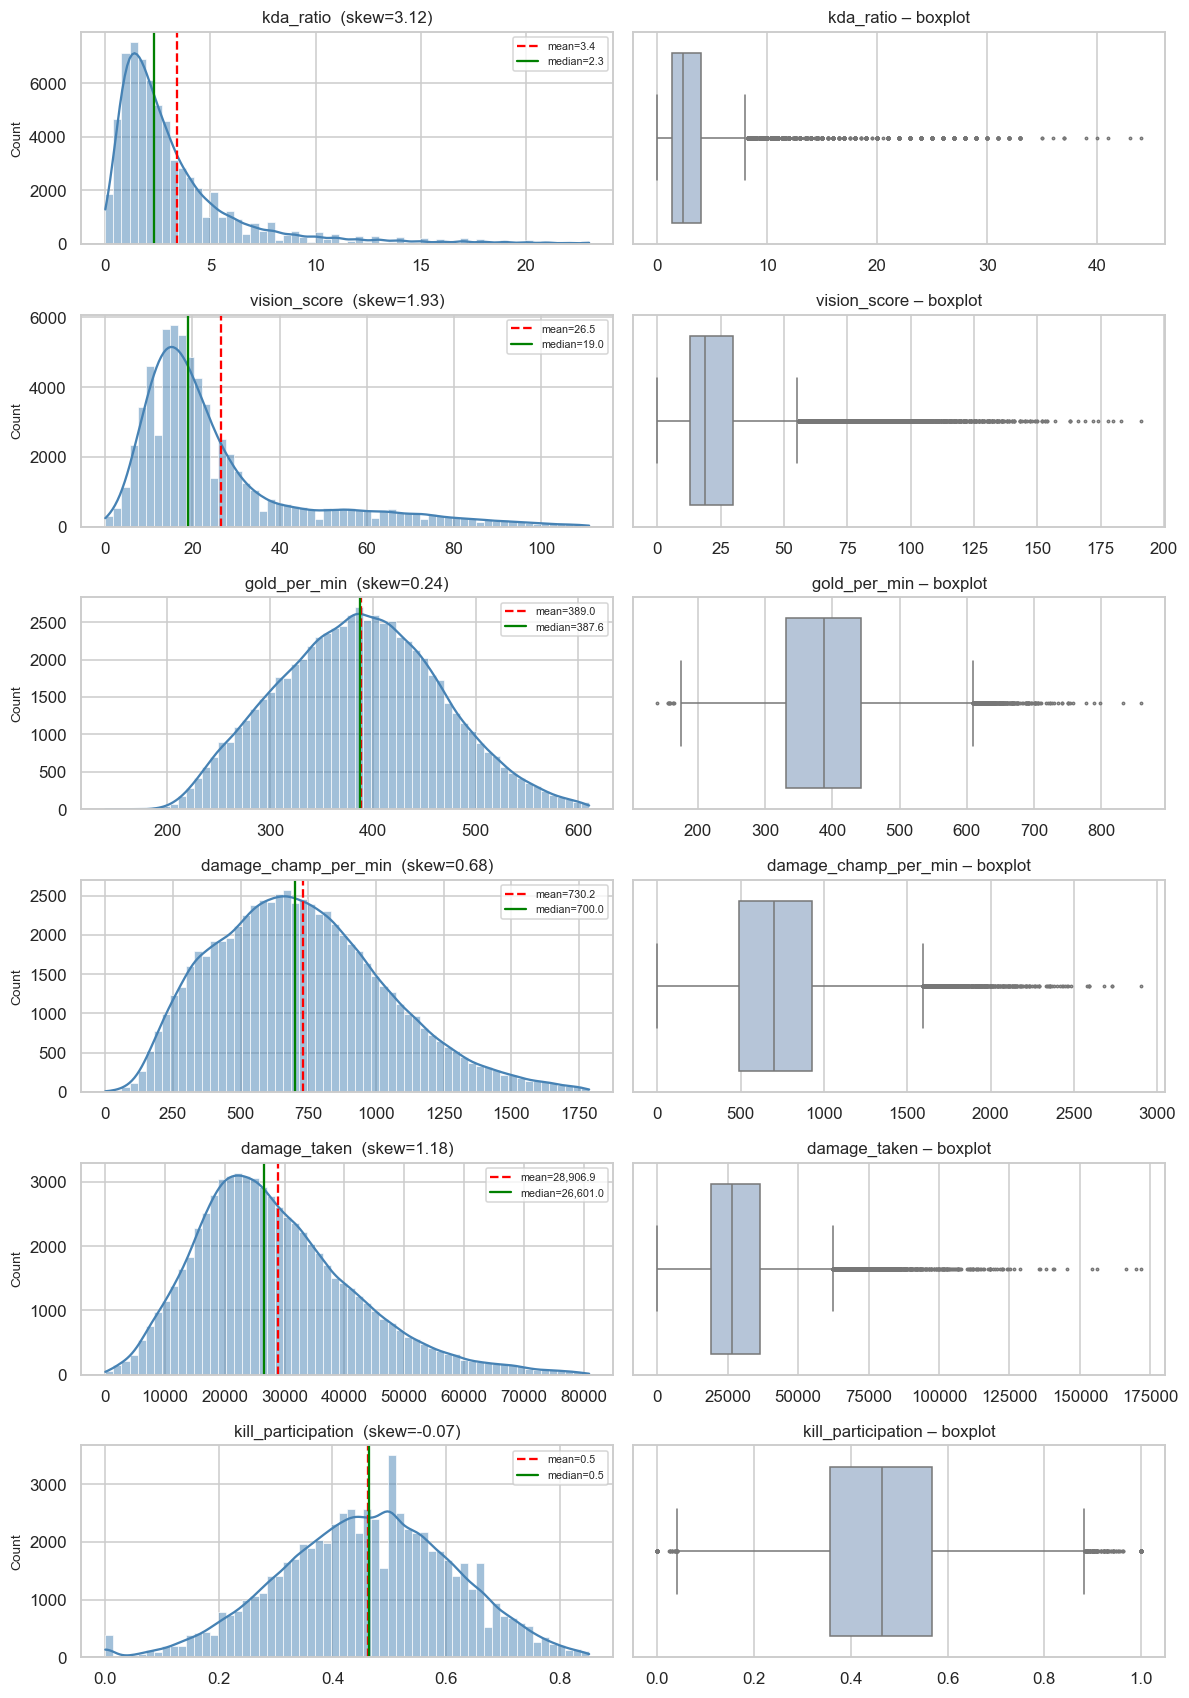

In [17]:
def plot_deep(data, cols, clip_q=0.995):
    fig, axes = plt.subplots(len(cols), 2, figsize=(11, 2.6 * len(cols)))
    axes = np.atleast_2d(axes)
    for (a_h, a_b), c in zip(axes, cols):
        s = data[c].dropna()
        view = s[s <= s.quantile(clip_q)]
        sns.histplot(view, bins=60, kde=True, ax=a_h, color="steelblue", edgecolor=None)
        a_h.axvline(s.mean(), color="red", ls="--", label=f"mean={s.mean():,.1f}")
        a_h.axvline(s.median(), color="green", label=f"median={s.median():,.1f}")
        a_h.set_title(f"{c}  (skew={s.skew():.2f})")
        a_h.set_xlabel("")
        a_h.legend(fontsize=7)
        sns.boxplot(x=s, ax=a_b, color="lightsteelblue", fliersize=1.5)
        a_b.set_title(f"{c} – boxplot")
        a_b.set_xlabel("")
    plt.tight_layout()
    plt.show()


plot_deep(df, DEEP_COLS)

#### B3. Biến đổi nào làm giảm lệch?
Skewness của mỗi cột sau khi biến đổi. Biến đổi chỉ để **so sánh**, chưa thay đổi dữ liệu.

In [18]:
from scipy import stats

tf = pd.DataFrame({
    "skew_raw": df[NUM_MAIN].skew(),
    "skew_log1p": np.log1p(df[NUM_MAIN]).skew(),
    "skew_sqrt": np.sqrt(df[NUM_MAIN]).skew(),
    "skew_yeojohnson": pd.Series({c: pd.Series(stats.yeojohnson(df[c])[0]).skew() for c in NUM_MAIN}),
})
tf["best"] = tf.drop(columns="skew_raw").abs().idxmin(axis=1)
tf["lệch mạnh (|skew|>1)"] = tf["skew_raw"].abs() > 1
display(tf)

,skew_raw,skew_log1p,skew_sqrt,skew_yeojohnson,best,lệch mạnh (|skew|>1)
kills,1.038,-0.580,-0.188,-0.044,skew_yeojohnson,True
deaths,0.387,-1.080,-0.690,-0.045,skew_yeojohnson,False
assists,1.244,-0.608,0.034,-0.016,skew_yeojohnson,True
kda_ratio,3.120,0.734,1.416,0.023,skew_yeojohnson,True
kill_participation,-0.071,-0.410,-1.150,0.000,skew_yeojohnson,False
vision_score,1.934,0.028,1.057,-0.002,skew_yeojohnson,True
gold_earned,0.305,-0.938,-0.225,0.011,skew_yeojohnson,False
gold_spent,0.396,-1.256,-0.257,0.037,skew_yeojohnson,False
gold_per_min,0.243,-0.308,-0.036,-0.010,skew_yeojohnson,False
damage_dealt,0.689,-1.052,-0.140,-0.102,skew_yeojohnson,False


### C. Relationships
#### C1. Tương quan giữa các cột số

gold_per_min == gold_earned/duration_min: True
damage_per_min == damage_dealt/duration_min: True
damage_champ_per_min == damage_to_champ/duration_min: True


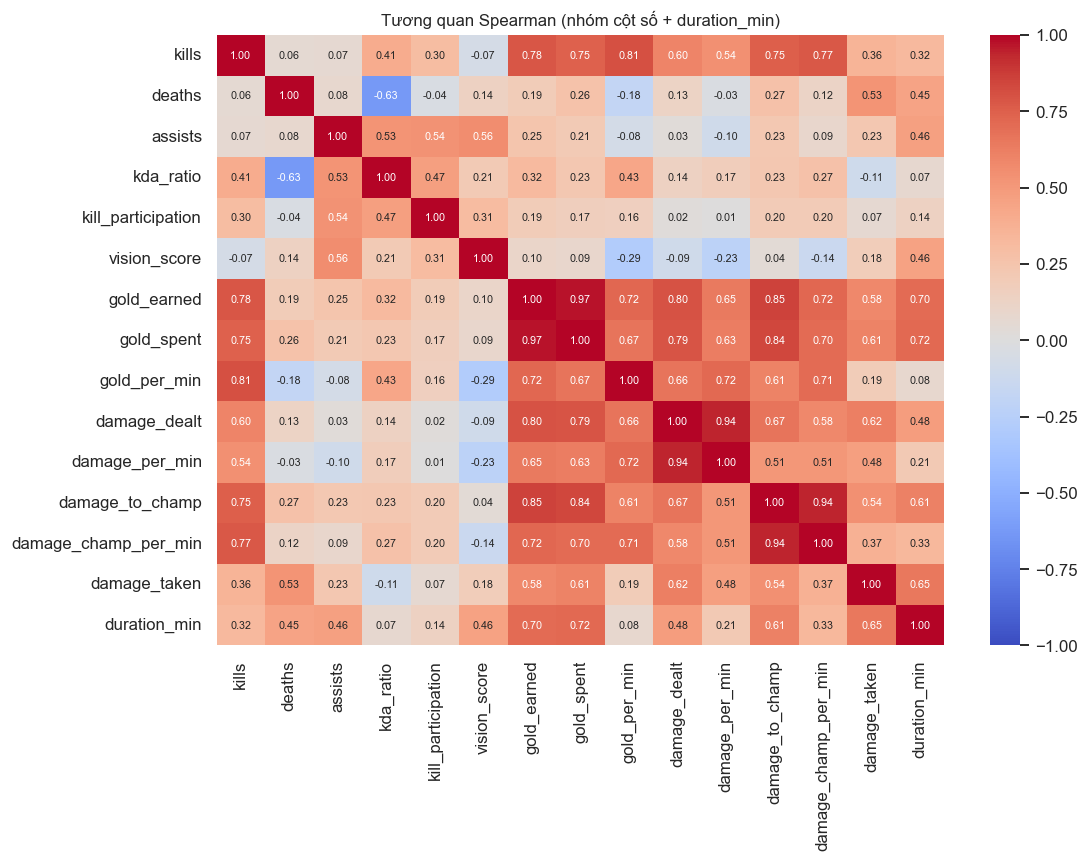

In [19]:
dm = df["duration_min"]
print("gold_per_min == gold_earned/duration_min:", np.allclose(df.gold_per_min, df.gold_earned / dm))
print("damage_per_min == damage_dealt/duration_min:", np.allclose(df.damage_per_min, df.damage_dealt / dm))
print("damage_champ_per_min == damage_to_champ/duration_min:", np.allclose(df.damage_champ_per_min, df.damage_to_champ / dm))

corr = df[NUM_MAIN + ["duration_min"]].corr(method="spearman")
plt.figure(figsize=(10.5, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Tương quan Spearman (nhóm cột số + duration_min)")
plt.tight_layout()
plt.show()

#### C2. Thống kê theo nhóm: role và thắng/thua

Median theo role:


,kda_ratio,vision_score,gold_per_min,damage_champ_per_min,damage_taken,kill_participation
position,,,,,,
TOP,1.778,16.000,398.117,783.023,"32,660.000",0.359
JUNGLE,2.571,21.000,407.576,659.376,"37,932.000",0.500
MIDDLE,2.250,17.000,401.949,818.316,"24,258.000",0.441
BOTTOM,2.286,15.000,422.206,798.000,"21,973.500",0.464
SUPPORT,2.750,59.000,291.569,386.554,"21,022.000",0.545


Median theo thắng/thua:


win,thua,thắng,chênh_%
kda_ratio,1.429,3.750,162.500
vision_score,19.000,20.000,5.263
gold_per_min,358.268,422.561,17.946
damage_champ_per_min,632.375,777.839,23.003
damage_taken,"27,698.500","25,395.500",-8.315
kill_participation,0.458,0.471,2.674


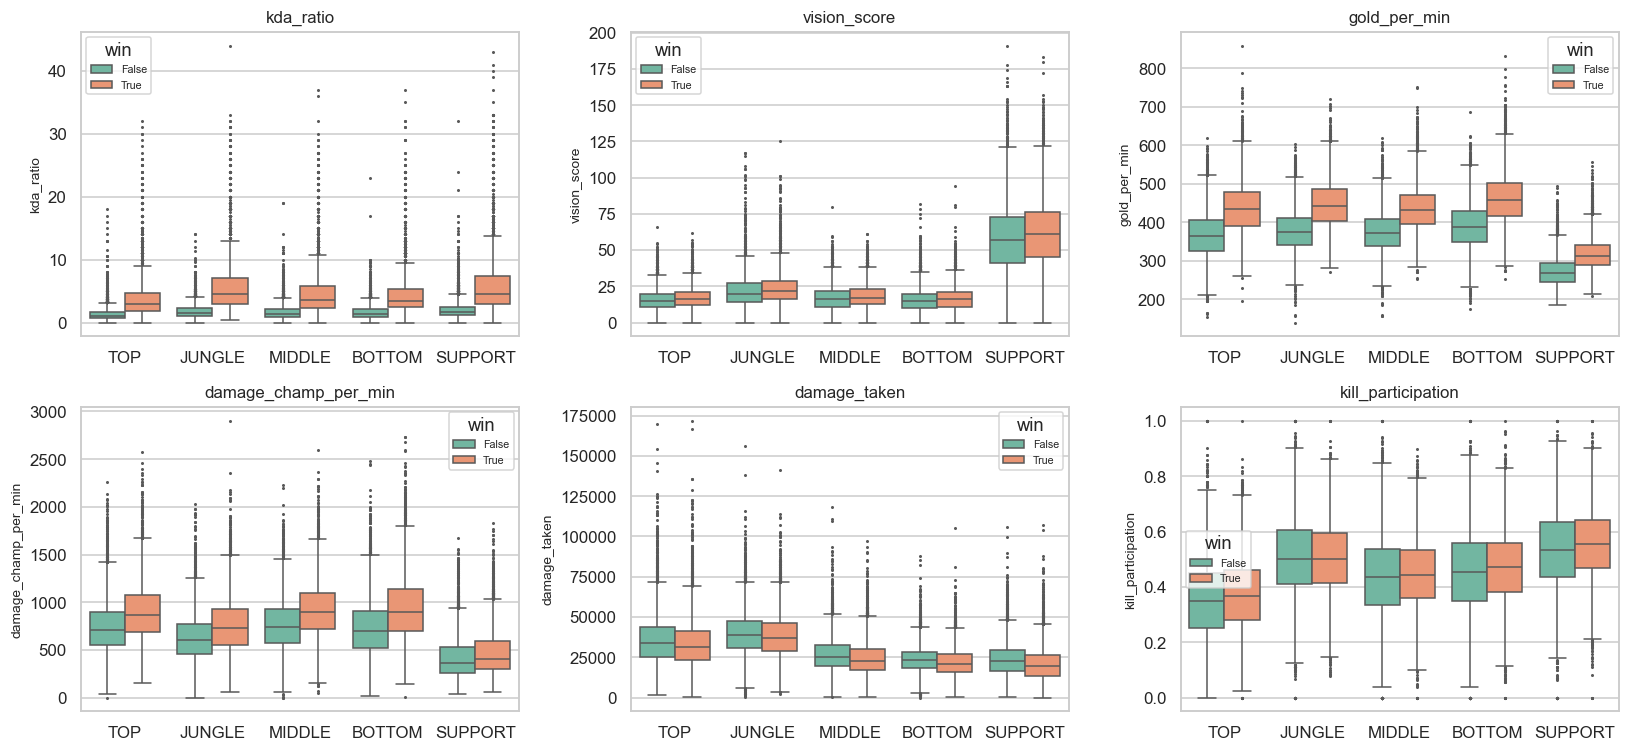

In [20]:
d_role = df[df["position"].isin(ROLE_ORDER)]
print("Median theo role:")
display(d_role.groupby("position")[DEEP_COLS].median().loc[ROLE_ORDER])

print("Median theo thắng/thua:")
by_win = df.groupby("win")[DEEP_COLS].median().T.rename(columns={False: "thua", True: "thắng"})
by_win["chênh_%"] = (by_win["thắng"] / by_win["thua"] - 1) * 100
display(by_win)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), DEEP_COLS):
    sns.boxplot(data=d_role, x="position", y=c, hue="win", order=ROLE_ORDER, ax=ax, fliersize=1, palette="Set2")
    ax.set_title(c)
    ax.set_xlabel("")
    ax.legend(title="win", fontsize=7)
plt.tight_layout()
plt.show()

### D. Giá trị vô lý, giá trị đặc biệt (placeholder) và trận ngắn

#### D1. Kiểm tra tính hợp lý
Mỗi dòng là một ràng buộc mà dữ liệu hợp lệ phải thỏa. Chạy trên toàn bộ dữ liệu.

In [21]:
df["is_early"] = df["duration"] < EARLY_SEC
df["n_empty_slots"] = (df[ITEM_SLOTS] == EMPTY).sum(axis=1)

kda_calc = (df.kills + df.assists) / df.deaths.clip(lower=1)
kp_calc = (df.kills + df.assists) / df.team_champKills.replace(0, np.nan)
ratio_spent = df.gold_spent / df.gold_earned

checks = {
    "Giá trị âm ở cột số": (df[NUM_MAIN] < 0).any(axis=1),
    "kda_ratio sai công thức": (df.kda_ratio - kda_calc).abs() > 1e-6,
    "kill_participation sai công thức / ngoài [0,1]": ((df.kill_participation - kp_calc).abs() > 1e-6) | (df.kill_participation > 1),
    "damage_to_champ > damage_dealt": df.damage_to_champ > df.damage_dealt,
    "gold_spent > 1.5 × gold_earned": ratio_spent > 1.5,
    "gold_spent > 2 × gold_earned": ratio_spent > 2.0,
    "damage_to_champ == 0": df.damage_to_champ == 0,
    "position ngoài 5 role (vd 'Invalid')": ~df.position.isin(ROLE_ORDER),
    "final_power/powerMax = 10000": (df.final_power >= 10000) | (df.final_powerMax >= 10000),
    "ô trang bị item0-5 = 'Item_0' (ô trống)": df.n_empty_slots > 0,
    "trận < 15 phút": df.is_early,
    "deaths == 0 (KDA = K+A)": df.deaths == 0,
}
logic_df = pd.DataFrame({"số dòng": {k: int(m.sum()) for k, m in checks.items()},
                         "% dòng": {k: m.mean() * 100 for k, m in checks.items()}})
display(logic_df)

sent = df[(df.final_power >= 10000) | (df.final_powerMax >= 10000)]
print("Champion có final_power = 10000:", sent.champion_name.value_counts().to_dict())
print("Giá trị Item_0 ở item6:", int((df.item6 == EMPTY).sum()), "| các giá trị item6:", df.item6.unique().tolist())
display(df.loc[ratio_spent > 2, ["game_id", "champion_name", "position", "duration_min", "gold_earned", "gold_spent"]])

,số dòng,% dòng
Giá trị âm ở cột số,0,0.000
kda_ratio sai công thức,0,0.000
"kill_participation sai công thức / ngoài [0,1]",0,0.000
damage_to_champ > damage_dealt,0,0.000
gold_spent > 1.5 × gold_earned,55,0.081
gold_spent > 2 × gold_earned,5,0.007
damage_to_champ == 0,7,0.010
position ngoài 5 role (vd 'Invalid'),3,0.004
final_power/powerMax = 10000,812,1.189
ô trang bị item0-5 = 'Item_0' (ô trống),28726,42.059


Champion có final_power = 10000: {'Viego': 812}
Giá trị Item_0 ở item6: 28 | các giá trị item6: ['Stealth Ward', 'Oracle Lens', 'Farsight Alteration', 'Scarecrow Effigy', 'Eye of the Herald', 'Item_0']


,game_id,champion_name,position,duration_min,gold_earned,gold_spent
14787,3739553029,Hwei,MIDDLE,26.917,9636,19805
22435,3745837346,Volibear,TOP,24.650,4866,11070
31886,3745571270,Talon,JUNGLE,30.083,12584,26500
38568,3746402492,Jinx,BOTTOM,24.933,8957,21540
50440,3746158908,Urgot,TOP,24.367,9622,44987


#### D2. Trận remake / đầu hàng sớm (< 15 phút)
Làm ở **mức trận** (mỗi trận 1 dòng) để không đếm trùng 10 lần. `duration` tính bằng giây nên 15 phút = 900.

count   6,830.000
mean       29.660
std         6.530
min         5.020
1%         15.200
5%         17.930
50%        29.500
95%        40.680
max        58.080


,số trận,% trận
ngưỡng (phút),,
5,0,0.000
10,28,0.410
12,42,0.615
15,59,0.864
18,345,5.051
20,521,7.628


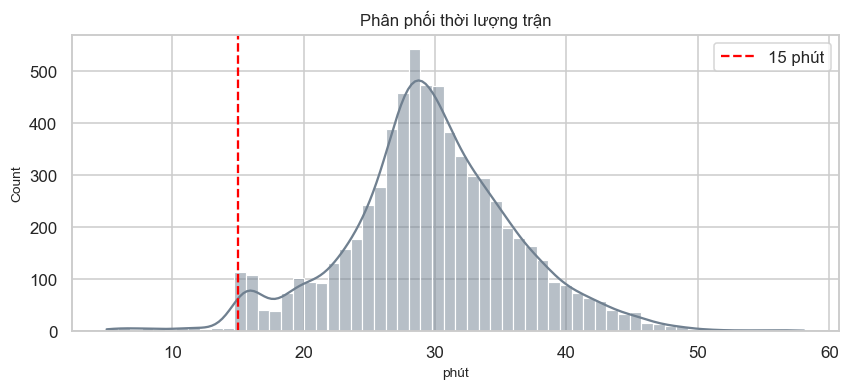

is_early,median >=15p,median <15p
kills,5.000,1.000
assists,7.000,1.000
gold_earned,"11,461.000","3,192.500"
gold_per_min,388.100,328.092
damage_to_champ,"20,595.500","2,593.500"
damage_champ_per_min,703.093,278.726
vision_score,19.000,3.000
n_empty_slots,0.000,2.000


Ảnh hưởng của trận sớm lên skew toàn cục:


,skew_tất_cả,skew_bỏ_trận_sớm
kills,1.038,1.036
deaths,0.387,0.396
assists,1.244,1.248
kda_ratio,3.120,3.117
kill_participation,-0.071,-0.057
vision_score,1.934,1.938
gold_earned,0.305,0.387
gold_spent,0.396,0.489
gold_per_min,0.243,0.243
damage_dealt,0.689,0.690


In [22]:
games = df.groupby("game_id").agg(duration=("duration", "first")).reset_index()
games["duration_min"] = games["duration"] / 60
print(games["duration_min"].describe(percentiles=[0.01, 0.05, 0.5, 0.95]).round(2).to_string())

sens = [{"ngưỡng (phút)": m, "số trận": int((games.duration < m * 60).sum()),
         "% trận": (games.duration < m * 60).mean() * 100} for m in [5, 10, 12, 15, 18, 20]]
display(pd.DataFrame(sens).set_index("ngưỡng (phút)"))

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.histplot(games.duration_min, bins=60, kde=True, ax=ax, color="slategray")
ax.axvline(15, color="red", ls="--", label="15 phút")
ax.set_title("Phân phối thời lượng trận")
ax.set_xlabel("phút")
ax.legend()
plt.show()

cmp_cols = ["kills", "assists", "gold_earned", "gold_per_min", "damage_to_champ", "damage_champ_per_min", "vision_score", "n_empty_slots"]
cmp = df.groupby("is_early")[cmp_cols].median().T.rename(columns={False: "median >=15p", True: "median <15p"})
display(cmp)

eff = pd.DataFrame({"skew_tất_cả": df[NUM_MAIN].skew(), "skew_bỏ_trận_sớm": df.loc[~df.is_early, NUM_MAIN].skew()})
print("Ảnh hưởng của trận sớm lên skew toàn cục:")
display(eff)

#### D3. Outlier: có phải lỗi hay là hiệu suất thật?
Dùng IQR 1.5×, IQR 3× và robust Z (MAD > 3.5; dùng thay z-score vì dữ liệu lệch phải). Chạy trên tập đã bỏ trận < 15 phút.

In [23]:
dc = df[~df.is_early].copy()


def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)


rows = []
for c in NUM_MAIN:
    s = dc[c]
    lo, hi = iqr_bounds(s)
    lo3, hi3 = iqr_bounds(s, 3)
    mad = np.median(np.abs(s - s.median()))
    rz = 0.6745 * (s - s.median()) / mad if mad > 0 else pd.Series(0.0, index=s.index)
    rows.append({"column": c, "IQR1.5 (số dòng)": int(((s < lo) | (s > hi)).sum()),
                 "IQR1.5_%": ((s < lo) | (s > hi)).mean() * 100,
                 "IQR3 (cực đoan)": int(((s < lo3) | (s > hi3)).sum()),
                 "robustZ>3.5": int((rz.abs() > 3.5).sum()),
                 "upper_fence": hi, "max": s.max()})
display(pd.DataFrame(rows).set_index("column"))

# Outlier cột raw có phải chỉ do trận dài?
rows = []
for c in ["gold_earned", "damage_to_champ", "damage_taken", "gold_per_min", "damage_champ_per_min"]:
    _, hi = iqr_bounds(dc[c])
    m = dc[c] > hi
    rows.append({"column": c, "n_outlier_cao": int(m.sum()),
                 "duration_TB_outlier (phút)": dc.loc[m, "duration_min"].mean(),
                 "duration_TB_còn_lại (phút)": dc.loc[~m, "duration_min"].mean()})
print("Thời lượng trung bình của nhóm outlier cao so với phần còn lại:")
display(pd.DataFrame(rows).set_index("column"))

# Xem trực tiếp các ca cực đoan của cột đi sâu
for c in DEEP_COLS:
    cols = list(dict.fromkeys(["game_id", "champion_name", "position", "duration_min", "kills", "deaths", "assists", c]))
    print(f"--- Top 3: {c}")
    display(dc.nlargest(3, c)[cols])

,IQR1.5 (số dòng),IQR1.5_%,IQR3 (cực đoan),robustZ>3.5,upper_fence,max
column,,,,,,
kills,1281,1.892,51,685,18.000,43.000
deaths,747,1.103,7,204,14.000,23.000
assists,1547,2.285,69,2372,24.000,53.000
kda_ratio,5212,7.698,2460,5062,8.000,44.000
kill_participation,478,0.706,0,0,0.879,1.000
vision_score,7744,11.437,2392,7744,55.500,191.000
gold_earned,587,0.867,4,111,"20,983.000","30,549.000"
gold_spent,599,0.885,44,194,"19,562.500","44,987.000"
gold_per_min,372,0.549,5,55,609.040,858.981


Thời lượng trung bình của nhóm outlier cao so với phần còn lại:


,n_outlier_cao,duration_TB_outlier (phút),duration_TB_còn_lại (phút)
column,,,
gold_earned,587,44.010,29.709
damage_to_champ,1548,40.347,29.587
damage_taken,1795,40.321,29.547
gold_per_min,365,26.905,29.849
damage_champ_per_min,970,34.558,29.764


--- Top 3: kda_ratio


,game_id,champion_name,position,duration_min,kills,deaths,assists,kda_ratio
5556,3741105405,Sejuani,JUNGLE,53.550,11,0,33,44.000
22884,3745328225,Xerath,SUPPORT,47.717,28,1,15,43.000
36389,3746307861,Yuumi,SUPPORT,39.367,4,1,37,41.000


--- Top 3: vision_score


... (5 outputs left out)

--- Top 3: damage_taken


,game_id,champion_name,position,duration_min,kills,deaths,assists,damage_taken
3285,3743100488,DrMundo,TOP,44.550,9,4,19,171747
61255,3743703256,DrMundo,TOP,42.100,9,7,12,170001
39945,3746361225,DrMundo,TOP,41.667,10,7,13,166504


--- Top 3: kill_participation


,game_id,champion_name,position,duration_min,kills,deaths,assists,kill_participation
3748,3745776128,Zeri,BOTTOM,16.917,3,6,0,1.000
6802,3745246317,Akshan,MIDDLE,22.450,5,3,0,1.000
9472,3745741928,Vladimir,MIDDLE,15.350,2,3,0,1.000


### Đánh giá và phân loại Outlier

Ta chia outlier thành 3 trường hợp:
- **(1) Outlier thật:** Hiệu suất đặc biệt, champion có chất tướng phù hợp hoặc tình huống gameplay hiếm nhưng hợp lệ.
- **(2) Outlier do thời lượng:** Giá trị cao chủ yếu do trận đấu kéo dài, chưa chắc hiệu suất vượt trội.
- **(3) Outlier nghi lỗi:** Có dấu hiệu bất thường về công thức, dữ liệu, đơn vị đo hoặc tính nhất quán.

**kills:** Có 1,281 dòng vượt IQR1.5 và 51 dòng vượt IQR3. Max = 43 khá hiếm nhưng vẫn có thể xảy ra trong những trận snowball mạnh hoặc chênh lệch trình độ đáng kể => **(1)**

**deaths:** Có 747 dòng vượt IQR1.5 và 7 dòng vượt IQR3. Max = 23 cao nhưng hợp lý trong những trận bị camp, thua lane nghiêm trọng hoặc kéo dài với nhiều giao tranh => **(1)**

**assists:** Có 1,547 dòng vượt IQR1.5 và 69 dòng vượt IQR3. Max = 53 hợp lý với Support/Jungle trong trận dài. Sejuani Jungle đạt 33 assists trong 53.55 phút là một ví dụ điển hình => **(1)(2)**

**kda_ratio:** Có 5,212 dòng vượt IQR1.5 và 2,460 dòng vượt IQR3. Max = 44, với các trường hợp Sejuani, Xerath và Yuumi có deaths thấp nhưng assists cao. Đây là outlier gameplay hợp lý, tuy nhiên cần kiểm tra công thức xử lý deaths = 0 => **(1)(3)**

**kill_participation:** Có 478 dòng vượt IQR1.5, max = 1.0. Các trường hợp Zeri, Akshan và Vladimir đạt KP = 100% là hợp lệ khi tham gia toàn bộ kills của đội. Cần kiểm tra nếu xuất hiện KP > 1 => **(1)**

**vision_score:** Có 7,744 dòng vượt IQR1.5 và 2,392 dòng vượt IQR3, tỷ lệ outlier cao nhất (11.437%). Max = 191, chủ yếu xuất hiện ở Support như Karma/Zyra trong trận 46–56 phút, phù hợp với vai trò và thời gian tích lũy vision => **(1)(2)**

**gold_earned:** Có 587 dòng vượt IQR1.5 và 4 dòng vượt IQR3. Max = 30,549. Duration trung bình của outlier đạt 44.010 phút, cao hơn 29.709 phút của nhóm còn lại, cho thấy trận dài góp phần tích lũy gold => **(1)(2)**

**gold_spent:** Có 599 dòng vượt IQR1.5 và 44 dòng vượt IQR3. Max = 44,987. Giá trị cao có thể xuất phát từ trận dài và lượng trang bị mua lớn, nhưng cần kiểm tra các trường hợp gold_spent > gold_earned để xác minh tính nhất quán => **(1)(2)(3)**

**gold_per_min:** Có 372 dòng vượt IQR1.5 và 5 dòng vượt IQR3. Max = 858.981. Duration trung bình của outlier chỉ 26.905 phút, thấp hơn nhóm còn lại (29.849 phút). Các trường hợp Irelia/Draven có kills cao, deaths thấp, cho thấy hiệu suất kiếm vàng và snowball mạnh => **(1)(3)**

**damage_dealt:** Có 983 dòng vượt IQR1.5 và 28 dòng vượt IQR3. Max = 675,166. Tổng damage cao có thể do trận dài và nhiều giao tranh; cần đối chiếu damage_per_min để phân biệt ảnh hưởng thời lượng với hiệu suất thực sự => **(1)(2)**

**damage_per_min:** Có 718 dòng vượt IQR1.5 nhưng chỉ 1 dòng vượt IQR3. Max = 16,324.242. Outlier có thể phản ánh hiệu suất gây sát thương đặc biệt, tuy nhiên cần kiểm tra công thức và đơn vị duration => **(1)(3)**

**damage_to_champ:** Có 1,548 dòng vượt IQR1.5 và 112 dòng vượt IQR3. Max = 120,936. Duration trung bình của outlier đạt 40.347 phút, cao hơn 29.587 phút của nhóm còn lại, cho thấy thời lượng trận đấu góp phần đáng kể vào tổng sát thương => **(1)(2)**

**damage_champ_per_min:** Có 970 dòng vượt IQR1.5 và 32 dòng vượt IQR3. Max = 2,902.464. Duration trung bình chỉ cao hơn nhóm còn lại khoảng 4.8 phút; các trường hợp Master Yi, Twitch và Samira có kills cao, cho thấy hiệu suất gây sát thương đặc biệt. Cần kiểm tra thêm công thức và đơn vị => **(1)(2)(3)**

**damage_taken:** Có 1,795 dòng vượt IQR1.5 và 179 dòng vượt IQR3. Max = 171,747. Duration trung bình của outlier đạt 40.321 phút so với 29.547 phút của nhóm còn lại. Các trường hợp cực đoan đều thuộc Dr. Mundo Top trong trận dài, phù hợp với đặc điểm champion chống chịu => **(1)(2)**

### Bảng tổng hợp phân loại Outlier

| Đặc trưng | (1) Outlier thật | (2) Do thời lượng trận | (3) Nghi lỗi dữ liệu |
|---|:---:|:---:|:---:|
| `kills` | ✓ | | |
| `deaths` | ✓ | | |
| `assists` | ✓ | ✓ | |
| `kda_ratio` | ✓ | | ✓ |
| `kill_participation` | ✓ | | |
| `vision_score` | ✓ | ✓ | |
| `gold_earned` | ✓ | ✓ | |
| `gold_spent` | ✓ | ✓ | ✓ |
| `gold_per_min` | ✓ | | ✓ |
| `damage_dealt` | ✓ | ✓ | |
| `damage_per_min` | ✓ | | ✓ |
| `damage_to_champ` | ✓ | ✓ | |
| `damage_champ_per_min` | ✓ | ✓ | ✓ |
| `damage_taken` | ✓ | ✓ | |

**Nhận xét chung:**
- Phần lớn outlier có thể được giải thích bằng gameplay hợp lệ, đặc điểm của champion hoặc hiệu suất thi đấu nổi bật.
- Các chỉ số tổng như `gold_earned`, `damage_to_champ`, `damage_taken` chịu ảnh hưởng đáng kể từ thời lượng trận đấu.
- Một số chỉ số như `kda_ratio`, `gold_spent`, `gold_per_min` và các chỉ số damage/min cần được kiểm tra thêm về công thức, đơn vị và tính nhất quán dữ liệu.

*Lưu ý: Đây là phân loại sơ bộ dựa trên thống kê và các mẫu quan sát được; chưa khẳng định các trường hợp nghi lỗi thực sự là lỗi dữ liệu.*

#### D4. Trang bị và chỉ số cuối trận `final_*`
Hai phần: (a) các ô trang bị `item0–item6` (dạng chuỗi, `Item_0` = ô trống); (b) các chỉ số tướng tại thời điểm kết thúc `final_*`. Các chỉ số `final_*` phụ thuộc mạnh vào champion và role (ví dụ tướng vật lý thường có `final_abilityPower` bằng 0), nên cần chú ý tỷ lệ số 0 (`zero_%`) khi đọc skew.

Số ô đã có trang bị (item0-5):


,số dòng,%
n_filled,,
0,66,0.097
1,40,0.059
2,123,0.180
3,1389,2.034
4,7514,11.001
5,19594,28.688
6,39574,57.941


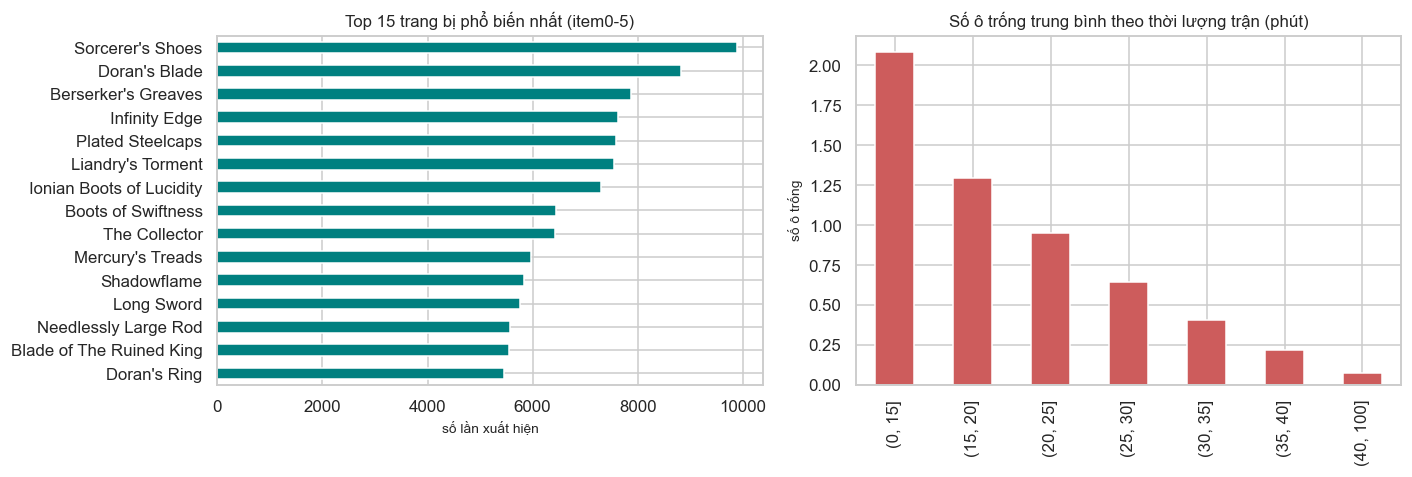

Số ô trống trung bình theo thời lượng:


,mean,count
duration_min,,
"(0, 15]",2.081,590
"(15, 20]",1.293,4620
"(20, 25]",0.949,8050
"(25, 30]",0.643,23550
"(30, 35]",0.409,18910
"(35, 40]",0.216,8490
"(40, 100]",0.077,4090


In [24]:
# (a) Ô trang bị
df["n_filled"] = 6 - df["n_empty_slots"]
print("Số ô đã có trang bị (item0-5):")
display(df["n_filled"].value_counts().sort_index().to_frame("số dòng").assign(**{"%": lambda x: x["số dòng"] / len(df) * 100}))

all_items = pd.concat([df[c] for c in ITEM_SLOTS])
top_items = all_items[all_items != EMPTY].value_counts().head(15)
dur_bin = pd.cut(df["duration_min"], [0, 15, 20, 25, 30, 35, 40, 100])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
top_items.sort_values().plot.barh(ax=axes[0], color="teal")
axes[0].set_title("Top 15 trang bị phổ biến nhất (item0-5)")
axes[0].set_xlabel("số lần xuất hiện")
df.groupby(dur_bin, observed=True)["n_empty_slots"].mean().plot.bar(ax=axes[1], color="indianred")
axes[1].set_title("Số ô trống trung bình theo thời lượng trận (phút)")
axes[1].set_xlabel("")
axes[1].set_ylabel("số ô trống")
plt.tight_layout()
plt.show()

print("Số ô trống trung bình theo thời lượng:")
display(df.groupby(dur_bin, observed=True)["n_empty_slots"].agg(["mean", "count"]))

Bỏ khỏi bảng (hằng số): ['final_abilityHaste']


,mean,median,IQR,min,max,skew,kurt,zero_%,skew_level
column,,,,,,,,,
final_abilityPower,135.090,37.000,230.000,0,1603,1.729,3.311,43.293,lệch mạnh
final_armor,121.901,103.000,57.000,24,927,2.733,13.922,0.000,lệch mạnh
final_attackDamage,193.884,150.000,175.000,50,1025,1.090,1.444,0.000,lệch mạnh
final_attackSpeed,173.816,152.000,66.000,37,1225,1.864,8.630,0.000,lệch mạnh
final_movementSpeed,410.703,398.000,36.000,119,1154,2.528,13.538,0.000,lệch mạnh
final_health,"1,244.050","1,163.000","2,193.000",0,10215,0.710,0.251,34.135,lệch vừa
final_healthMax,"2,765.109","2,589.000",894.250,661,10694,1.907,7.216,0.000,lệch mạnh
final_lifesteal,2.468,0.000,3.000,0,100,3.323,26.606,72.836,lệch mạnh
final_omnivamp,0.056,0.000,0.000,0,25,14.845,243.607,99.442,lệch mạnh


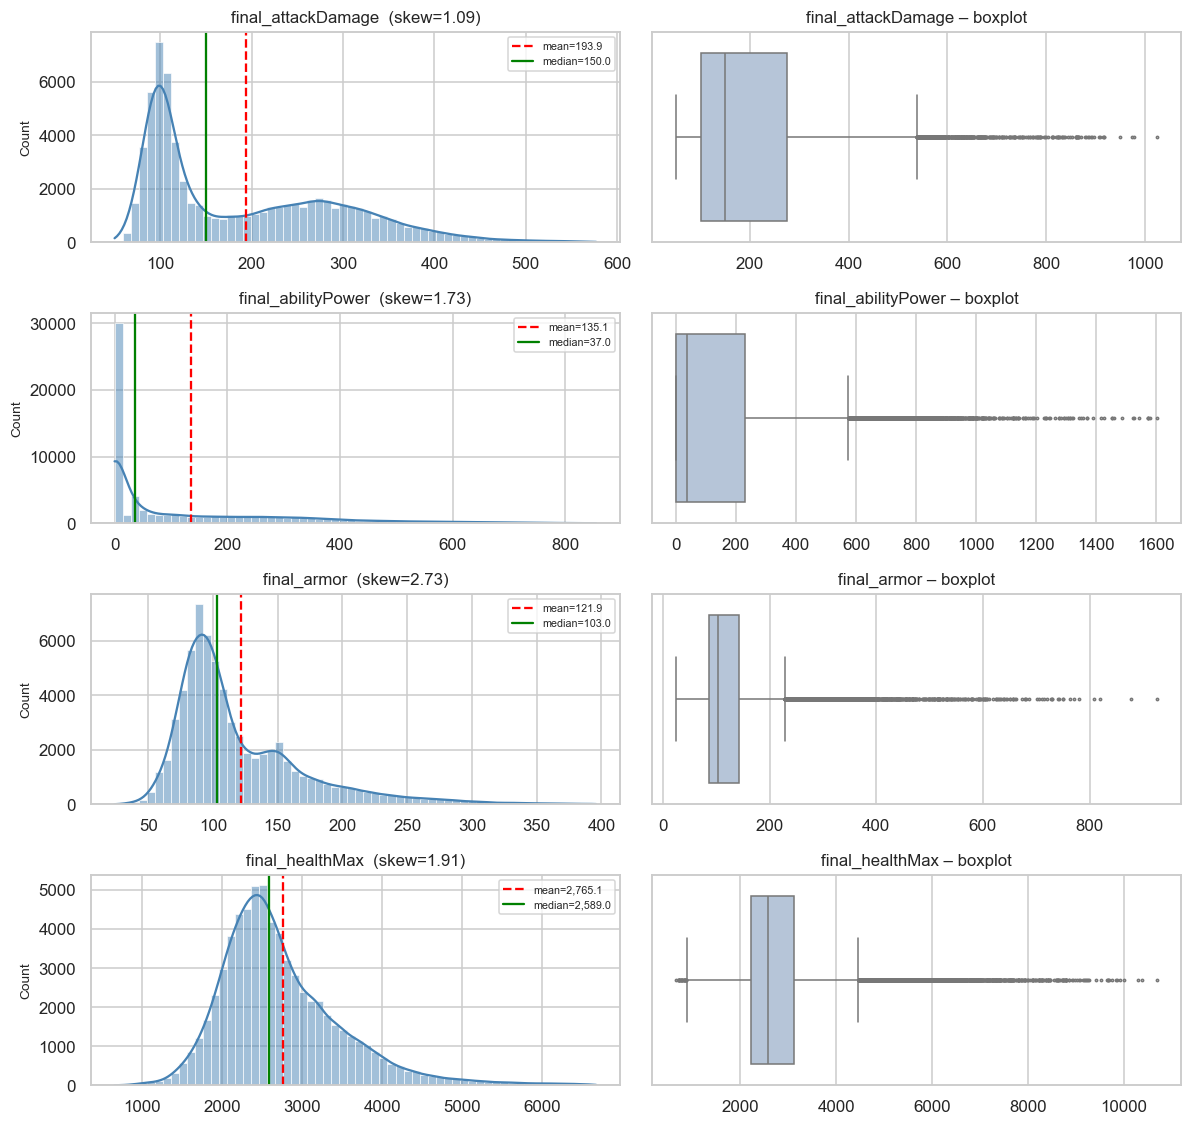

In [25]:
# (b) Chỉ số cuối trận final_*
final_use = [c for c in FINAL_COLS if c not in const_cols]
print("Bỏ khỏi bảng (hằng số):", [c for c in FINAL_COLS if c in const_cols])
final_summary = describe_shape(df, final_use)
display(final_summary[["mean", "median", "IQR", "min", "max", "skew", "kurt", "zero_%", "skew_level"]])

plot_deep(df, ["final_attackDamage", "final_abilityPower", "final_armor", "final_healthMax"])

Median theo role:


,final_attackDamage,final_abilityPower,final_armor,final_healthMax,final_movementSpeed
position,,,,,
TOP,198.000,0.000,133.000,"3,262.000",400.000
JUNGLE,213.000,0.000,120.000,"2,827.000",402.000
MIDDLE,105.000,316.000,99.000,"2,539.500",395.000
BOTTOM,281.000,0.000,89.000,"2,309.000",390.000
SUPPORT,95.000,110.000,95.000,"2,411.000",395.000


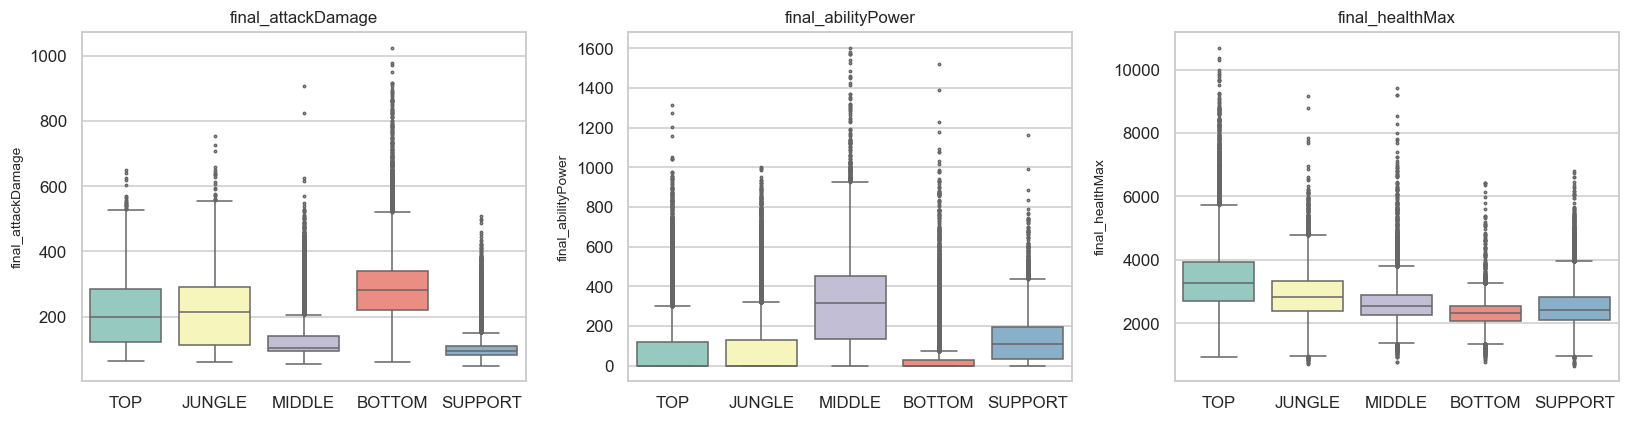

final_health == 0: 34.1% số dòng
final_health == final_healthMax: 20.6% số dòng
Tương quan final_health với win: 0.394
Tương quan final_healthMax với win: 0.13


In [26]:
# final_* theo role, và kiểm tra final_health
FINAL_ROLE = ["final_attackDamage", "final_abilityPower", "final_armor", "final_healthMax", "final_movementSpeed"]
print("Median theo role:")
display(d_role.groupby("position")[FINAL_ROLE].median().loc[ROLE_ORDER])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["final_attackDamage", "final_abilityPower", "final_healthMax"]):
    sns.boxplot(data=d_role, x="position", y=c, order=ROLE_ORDER, ax=ax, fliersize=1.5, palette="Set3")
    ax.set_title(c)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

print("final_health == 0:", f"{(df.final_health == 0).mean():.1%} số dòng")
print("final_health == final_healthMax:", f"{(df.final_health == df.final_healthMax).mean():.1%} số dòng")
print("Tương quan final_health với win:", round(df["final_health"].corr(df["win"].astype(int)), 3))
print("Tương quan final_healthMax với win:", round(df["final_healthMax"].corr(df["win"].astype(int)), 3))

#### Phân tích các chỉ số `final_*` có tỷ lệ giá trị 0 cao

Qua thống kê, một số chỉ số có tỷ lệ giá trị bằng 0 rất cao, nổi bật là `final_spellVamp` (99.974%), `final_omnivamp` (99.442%) và `final_lifesteal` (72.836%). Ngoài ra, `final_abilityPower` cũng có 43.293% giá trị bằng 0.

Điều này phản ánh đặc điểm của hệ thống tướng trong game: không phải champion nào cũng sử dụng hoặc sở hữu các chỉ số này. Chẳng hạn, những tướng thiên về sát thương vật lý thường không có Ability Power, trong khi Spell Vamp và Omnivamp chỉ xuất hiện ở một số trường hợp nhất định.

Do đó, cần thận trọng khi diễn giải độ lệch (skew) của các cột này. Skew cao không nhất thiết đồng nghĩa với việc dữ liệu có nhiều outlier bất thường, mà có thể xuất phát từ việc phần lớn giá trị tập trung tại 0, chỉ một tỷ lệ nhỏ có giá trị dương. Vì vậy, nên kết hợp `zero_%`, median và biểu đồ phân phối để đánh giá bản chất dữ liệu thay vì chỉ dựa vào skew.

#### Sự khác biệt về phân phối chỉ số giữa các role

Bảng median và boxplot cho thấy các chỉ số cuối trận có sự khác biệt đáng kể giữa các role, thể hiện rõ đặc trưng gameplay của từng vị trí:

- **TOP:** Có `final_healthMax` và `final_armor` tương đối cao, phản ánh xu hướng sử dụng các champion có khả năng chống chịu tốt.
- **JUNGLE:** Có median `final_attackDamage` khá cao (213), trong khi `final_abilityPower` bằng 0, cho thấy sự phổ biến của các tướng thiên về sát thương vật lý trong dữ liệu.
- **MIDDLE:** Có `final_abilityPower` cao nhất (median 316), phù hợp với đặc điểm của nhiều pháp sư đảm nhiệm vị trí đường giữa.
- **BOTTOM:** Có `final_attackDamage` cao nhất (median 281), phản ánh đặc trưng của các xạ thủ tập trung vào sát thương vật lý.
- **SUPPORT:** Có `final_attackDamage` thấp (median 95), trong khi `final_abilityPower` đạt median 110, cho thấy sự đa dạng về nhóm champion hỗ trợ.

Như vậy, phân phối các chỉ số `final_*` không đồng nhất giữa các role mà phụ thuộc đáng kể vào đặc điểm champion và vị trí thi đấu. Nếu so sánh trực tiếp giữa những người chơi thuộc các role khác nhau, kết quả có thể bị ảnh hưởng bởi sự khác biệt về bản chất tướng thay vì hiệu suất thực tế.

Vì vậy, nếu sử dụng các chỉ số này trong phân tích hoặc xây dựng mô hình, nên cân nhắc chuẩn hóa theo role hoặc champion. Trong đó, chuẩn hóa theo champion có thể kiểm soát tốt hơn sự khác biệt về chỉ số cơ bản và đặc điểm của từng tướng.

#### Phân biệt `final_health` và `final_healthMax`

Hai chỉ số này phản ánh hai khía cạnh khác nhau của trạng thái tướng tại thời điểm kết thúc trận:

- `final_health`: Lượng máu hiện tại còn lại của champion khi trận đấu kết thúc.
- `final_healthMax`: Tổng lượng máu tối đa mà champion có thể đạt được tại thời điểm đó.

Kết quả thống kê cho thấy 34.1% số dòng có `final_health = 0`, trong khi chỉ 20.6% số dòng có `final_health = final_healthMax`. Điều này cho thấy trạng thái máu của người chơi khi kết thúc trận khá đa dạng, bao gồm cả trường hợp bị hạ gục và trường hợp còn đầy máu.

Đáng chú ý, hệ số tương quan giữa `final_health` và `win` đạt 0.394, cao hơn đáng kể so với `final_healthMax` và `win` (0.130). Điều này cho thấy lượng máu còn lại có mối liên hệ với kết quả trận đấu rõ hơn so với khả năng chống chịu tối đa về mặt chỉ số.

Về việc sử dụng làm đặc trưng, cả hai chỉ số đều có giá trị phân tích. Tuy nhiên, cần phân biệt mục tiêu sử dụng: `final_healthMax` phản ánh đặc điểm xây dựng sức mạnh và khả năng chống chịu, còn `final_health` phản ánh trạng thái thực tế của người chơi khi trận đấu kết thúc. Đặc biệt, nếu xây dựng mô hình dự đoán chiến thắng từ dữ liệu trước hoặc trong trận, không nên sử dụng `final_health` vì đây là thông tin chỉ có được sau khi trận đấu kết thúc và có nguy cơ gây rò rỉ dữ liệu (data leakage).

#### Mối quan hệ giữa số ô trang bị trống và thời lượng trận

Kết quả thống kê cho thấy số ô trang bị trống trung bình giảm liên tục theo thời lượng trận. Cụ thể, ở những trận đấu kéo dài không quá 15 phút, số ô trống trung bình là 2.081. Trong khi đó, ở các trận kéo dài trên 40 phút, con số này chỉ còn 0.077.

Xu hướng này có thể được giải thích bởi việc người chơi có nhiều thời gian tích lũy vàng và mua sắm trang bị hơn khi trận đấu kéo dài. Ngược lại, trong các trận đấu ngắn, người chơi thường chưa có đủ thời gian để hoàn thành bộ trang bị.

Điều này cho thấy `n_filled` có mối quan hệ chặt chẽ với `duration_min`, do đó không hoàn toàn phản ánh sức mạnh hay hiệu suất của người chơi một cách độc lập. Nếu sử dụng `n_filled` làm đặc trưng trong mô hình, mô hình có thể học được ảnh hưởng của thời lượng trận thay vì chỉ học được khả năng tích lũy và xây dựng trang bị.

Vì vậy, cần xem xét `n_filled` trong mối tương quan với thời lượng trận. Có thể phân tích số lượng trang bị theo từng nhóm thời lượng hoặc chuẩn hóa theo thời lượng để đánh giá công bằng hơn giữa các trận đấu có độ dài khác nhau.

**Kết luận:** Các chỉ số cuối trận và trang bị đều mang thông tin hữu ích, nhưng chịu ảnh hưởng đáng kể từ champion, role và thời lượng trận. Do đó, khi sử dụng chúng cho các phân tích tiếp theo hoặc xây dựng mô hình dự đoán, cần xem xét các yếu tố này để tránh nhầm lẫn giữa đặc điểm vốn có của tướng, diễn biến trận đấu và hiệu suất thực tế của người chơi.

### E. Tiền xử lý 


| Bước | Quy tắc | Lý do |
|---|---|---|
| S1 | Loại **cả trận** có duration < 15 phút | Trận chưa chơi hoàn chỉnh; loại từng dòng sẽ làm hỏng cấu trúc 10 người/trận |
| S2 | `position` ngoài 5 role → gán theo `participant_id % 5` + cờ | Quy luật khớp với phần lớn dòng hợp lệ |
| S3 | Bỏ cột hằng số | Không có phương sai |
| S4 | `final_power/powerMax = 10000` → NaN | Giá trị placeholder, không phải mana thật |
| S5 | `gold_spent > 2×gold_earned` → NaN; 1.5–2× chỉ gắn cờ | Vô lý về kinh tế |
| S6 | `Item_0` → NaN, tạo `n_items_filled` | Là ô trống chứ không phải trang bị |
| S7 | Cờ nghi AFK / deaths = 0 (không loại) | Heuristic, tránh loại nhầm |
| S8 | Winsorize theo role (0.5%–99.5%) → `*_w`; `log1p` cho cột còn lệch mạnh | Outlier chủ yếu là hiệu suất thật nên không xóa |

In [27]:
ROLE_MAP = {0: "SUPPORT", 1: "TOP", 2: "JUNGLE", 3: "MIDDLE", 4: "BOTTOM"}
WINSOR_COLS = ["kills", "assists", "kda_ratio", "vision_score", "gold_per_min",
               "damage_per_min", "damage_champ_per_min", "damage_taken"]

valid = raw[raw.position.isin(ROLE_ORDER)]
acc = (valid.participant_id % 5).map(ROLE_MAP).eq(valid.position).mean()
print(f"Kiểm chứng S2: participant_id % 5 khớp position ở {acc:.1%} dòng hợp lệ")


def preprocess(raw_df, min_duration=EARLY_SEC, wq=(0.005, 0.995), gold_nan=2.0, gold_flag=1.5, sentinel=10000, skew_thr=1.0):
    d = raw_df.copy()
    d["duration_min"] = d["duration"] / 60
    log = []

    def step(name, before, after, why):
        log.append({"bước": name, "dòng trước": before, "dòng sau": after, "thay đổi": after - before, "ghi chú": why})

    # S1
    n0 = len(d)
    ids = d.loc[d.duration < min_duration, "game_id"].unique()
    d = d[~d.game_id.isin(ids)].copy()
    step("S1 loại trận ngắn", n0, len(d), f"{len(ids)} trận < {min_duration // 60} phút")

    # S2
    n0 = len(d)
    bad = ~d.position.isin(ROLE_ORDER)
    d["flag_position_imputed"] = bad
    d.loc[bad, "position"] = (d.loc[bad, "participant_id"] % 5).map(ROLE_MAP)
    step("S2 sửa position", n0, len(d), f"{int(bad.sum())} dòng được gán lại (không xóa dòng)")

    # S3
    n0 = len(d)
    const = [c for c in NUM_MAIN + FINAL_COLS if d[c].nunique() == 1]
    d = d.drop(columns=const)
    step("S3 bỏ cột hằng số", n0, len(d), f"bỏ cột {const}")

    # S4
    n0 = len(d)
    n4 = 0
    for c in ["final_power", "final_powerMax"]:
        m = d[c] >= sentinel
        n4 += int(m.sum())
        d.loc[m, c] = np.nan
    step("S4 placeholder -> NaN", n0, len(d), f"{n4} ô đổi thành NaN (không xóa dòng)")

    # S5
    n0 = len(d)
    ratio = d.gold_spent / d.gold_earned
    d["flag_gold_spent_suspect"] = ratio > gold_flag
    m = ratio > gold_nan
    d.loc[m, "gold_spent"] = np.nan
    step("S5 gold_spent vô lý", n0, len(d), f"{int(m.sum())} ô -> NaN; {int(d.flag_gold_spent_suspect.sum())} dòng gắn cờ")

    # S6
    n0 = len(d)
    for c in ITEM_COLS:
        d[c] = d[c].replace(EMPTY, np.nan)
    d["n_items_filled"] = d[ITEM_SLOTS].notna().sum(axis=1)
    step("S6 ô trống -> NaN", n0, len(d), f"{int((d.n_items_filled < 6).sum())} dòng có ít nhất 1 ô trống")

    # S7
    n0 = len(d)
    g = d.groupby("game_id")
    rel_gpm = d.gold_per_min / g.gold_per_min.transform("median")
    rel_dmg = d.damage_champ_per_min / g.damage_champ_per_min.transform("median")
    d["flag_afk_suspect"] = (rel_gpm < 0.5) & (rel_dmg < 0.2)
    d["flag_deaths_zero"] = d.deaths == 0
    step("S7 gắn cờ", n0, len(d), f"AFK nghi ngờ: {int(d.flag_afk_suspect.sum())}; deaths=0: {int(d.flag_deaths_zero.sum())}")

    # S8
    n0 = len(d)
    for c in WINSOR_COLS:
        lo = d.groupby("position")[c].transform(lambda s: s.quantile(wq[0]))
        hi = d.groupby("position")[c].transform(lambda s: s.quantile(wq[1]))
        d[c + "_w"] = d[c].clip(lo, hi)
    skewed = [c for c in WINSOR_COLS if abs(d[c + "_w"].skew()) > skew_thr]
    for c in skewed:
        d[c + "_log1p"] = np.log1p(d[c + "_w"])
    step("S8 winsorize + log1p", n0, len(d), f"log1p cho {skewed}")

    return d, pd.DataFrame(log).set_index("bước")


df_clean, step_log = preprocess(raw)
display(step_log)
print(f"\nTổng: {len(raw):,} -> {len(df_clean):,} dòng | {raw.game_id.nunique():,} -> {df_clean.game_id.nunique():,} trận")
assert (df_clean.groupby("game_id").size() == 10).all(), "Có trận không đủ 10 người"
print("Mỗi trận còn đủ 10 người: OK")

Kiểm chứng S2: participant_id % 5 khớp position ở 97.7% dòng hợp lệ


,dòng trước,dòng sau,thay đổi,ghi chú
bước,,,,
S1 loại trận ngắn,68300,67710,-590,59 trận < 15 phút
S2 sửa position,67710,67710,0,3 dòng được gán lại (không xóa dòng)
S3 bỏ cột hằng số,67710,67710,0,bỏ cột ['final_abilityHaste']
S4 placeholder -> NaN,67710,67710,0,1573 ô đổi thành NaN (không xóa dòng)
S5 gold_spent vô lý,67710,67710,0,5 ô -> NaN; 55 dòng gắn cờ
S6 ô trống -> NaN,67710,67710,0,28196 dòng có ít nhất 1 ô trống
S7 gắn cờ,67710,67710,0,AFK nghi ngờ: 10; deaths=0: 1224
S8 winsorize + log1p,67710,67710,0,"log1p cho ['assists', 'kda_ratio', 'vision_sco..."



Tổng: 68,300 -> 67,710 dòng | 6,830 -> 6,771 trận
Mỗi trận còn đủ 10 người: OK


**Kiểm tra hiệu quả:** skew trước và sau winsorize / log1p.

In [28]:
rows = []
for c in WINSOR_COLS:
    rows.append({"column": c, "skew_gốc": raw[c].skew(), "skew_sau_S1": df_clean[c].skew(),
                 "skew_sau_winsor": df_clean[c + "_w"].skew(),
                 "skew_sau_log1p": df_clean[c + "_log1p"].skew() if c + "_log1p" in df_clean else np.nan,
                 "max_gốc": raw[c].max(), "max_sau_winsor": df_clean[c + "_w"].max()})
display(pd.DataFrame(rows).set_index("column"))

SAVE_OUTPUT = False       # đổi True để lưu ra data/processed/
if SAVE_OUTPUT:
    out_dir = DATA_PATH.parent.parent / "processed" if DATA_PATH.parent.name == "raw" else DATA_PATH.parent / "processed"
    out_dir.mkdir(parents=True, exist_ok=True)
    df_clean.to_csv(out_dir / "lol_numeric_clean.csv", index=False)
    print("Đã lưu:", out_dir / "lol_numeric_clean.csv")

,skew_gốc,skew_sau_S1,skew_sau_winsor,skew_sau_log1p,max_gốc,max_sau_winsor
column,,,,,,
kills,1.038,1.036,0.953,NaN,43.000,25.000
assists,1.244,1.248,1.207,-0.588,53.000,36.705
kda_ratio,3.120,3.117,2.832,0.733,44.000,26.000
vision_score,1.934,1.938,1.903,0.287,191.000,134.000
gold_per_min,0.243,0.243,0.208,NaN,858.981,649.003
damage_per_min,0.285,0.279,0.263,NaN,"16,324.242","13,785.980"
damage_champ_per_min,0.684,0.691,0.611,NaN,"2,902.464","1,962.928"
damage_taken,1.181,1.223,1.031,-0.494,"171,747.000","97,768.560"


## Tổng kết 

### Số liệu tự tổng hợp 

In [29]:
top_skew = summary["skew"].abs().sort_values(ascending=False).head(5)
n_games = df.game_id.nunique()
n_early = int((games.duration < EARLY_SEC).sum())

print(f"- Dữ liệu: {len(df):,} dòng, {n_games:,} trận; không missing trong nhóm cột này.")
print("- Cột lệch mạnh nhất: " + ", ".join(f"{k} ({summary.loc[k, 'skew']:.2f})" for k in top_skew.index))
print(f"- Trận < 15 phút: {n_early} trận ({n_early / n_games:.2%}).")
print(f"- Cột hằng số: {const_cols}")
print(f"- Sau tiền xử lý còn {len(df_clean):,} dòng ({len(df_clean) / len(raw):.2%}).")
print("\nVấn đề chất lượng dữ liệu phát hiện được:")
display(logic_df[logic_df["số dòng"] > 0])

- Dữ liệu: 68,300 dòng, 6,830 trận; không missing trong nhóm cột này.
- Cột lệch mạnh nhất: kda_ratio (3.12), vision_score (1.93), assists (1.24), damage_taken (1.18), damage_to_champ (1.08)
- Trận < 15 phút: 59 trận (0.86%).
- Cột hằng số: ['final_abilityHaste']
- Sau tiền xử lý còn 67,710 dòng (99.14%).

Vấn đề chất lượng dữ liệu phát hiện được:


,số dòng,% dòng
gold_spent > 1.5 × gold_earned,55,0.081
gold_spent > 2 × gold_earned,5,0.007
damage_to_champ == 0,7,0.010
position ngoài 5 role (vd 'Invalid'),3,0.004
final_power/powerMax = 10000,812,1.189
ô trang bị item0-5 = 'Item_0' (ô trống),28726,42.059
trận < 15 phút,590,0.864
deaths == 0 (KDA = K+A),1429,2.092


# Kết luận

## 1. Những phát hiện chính từ dữ liệu

### 1.1. Các chỉ số có phân phối khác nhau

Dữ liệu thể hiện hai nhóm phân phối chính:

- **Nhóm tương đối đối xứng:** Các chỉ số kinh tế và damage theo phút, tiêu biểu là `gold_per_min` (skew = 0.24), có mean = 389 gần bằng median = 388.
- **Nhóm lệch phải:** Các chỉ số như `kda_ratio` (3.12), `vision_score` (1.93), `assists` (1.24), `damage_taken` (1.18) và `damage_to_champ` (1.08) có nhiều giá trị lớn, khiến mean cao hơn median. Ví dụ, mean của `kda_ratio` là 3.42, cao hơn median 2.30 khoảng 48.7%.

**Ý nghĩa:** Không nên sử dụng mean để đại diện cho tất cả các chỉ số. Với những biến lệch phải, median thường phản ánh giá trị điển hình tốt hơn. Ngoài ra, cần kết hợp skew với histogram và IQR để xác định liệu các giá trị lớn có phải outlier bất thường hay chỉ phản ánh những trường hợp thi đấu có hiệu suất cao.

### 1.2. Role ảnh hưởng lớn đến các chỉ số

Các vị trí có đặc điểm thống kê khác nhau rõ rệt. Ví dụ:

| Chỉ số | Support | Các role còn lại |
|---|---:|---:|
| `vision_score` (median) | 59 | 15–21 |
| `gold_per_min` (median) | 292 | 398–422 |
| `damage_champ_per_min` (median) | 387 | 659–818 |

Support có vision score cao hơn nhưng lượng vàng và sát thương gây lên tướng thấp hơn các role khác. Điều này phù hợp với sự khác biệt về nhiệm vụ trong trận đấu.

**Ý nghĩa:** Tỷ lệ outlier cao của `vision_score` (11.4% theo IQR) có thể xuất phát từ sự khác biệt giữa các role, thay vì dữ liệu bất thường. Cần tính IQR riêng cho từng role để xác nhận.

### 1.3. Đội thắng và đội thua có sự khác biệt rõ rệt

Khác biệt lớn xuất hiện ở KDA và hiệu suất theo phút:

| Chỉ số (median) | Đội thắng | Đội thua | Chênh lệch |
|---|---:|---:|---:|
| `kda_ratio` | 3.75 | 1.43 | +162% |
| `damage_champ_per_min` | — | — | +23% |
| `gold_per_min` | — | — | +18% |
| `vision_score` | — | — | +5% |
| `kill_participation` | — | — | +2.7% |

*Lưu ý: Một số chỉ số chưa có giá trị median cụ thể trong bảng tổng hợp.*

**Ý nghĩa:** KDA và hiệu suất gây sát thương, kiếm vàng theo phút có sự khác biệt đáng kể giữa hai nhóm thắng và thua. Tuy nhiên, đây là các chỉ số được ghi nhận trong hoặc sau trận đấu, nên chỉ thể hiện mối liên hệ với kết quả thắng/thua, không chứng minh chúng là nguyên nhân trực tiếp dẫn đến chiến thắng.

### 1.4. Thời lượng trận ảnh hưởng đến các chỉ số tổng

Các chỉ số dạng tổng như `gold_earned`, `damage_to_champ` và `damage_taken` thường tăng khi trận đấu kéo dài.

Ví dụ, nhóm outlier của `gold_earned` có thời lượng trận trung bình **44.0 phút**, trong khi nhóm còn lại chỉ **29.7 phút**.

Ngoài ra, các chỉ số dạng `*_per_min` được tính bằng chỉ số tổng chia cho thời lượng trận (đơn vị phút). Vì vậy, hai nhóm cột này có quan hệ phụ thuộc trực tiếp về mặt công thức.

**Ý nghĩa:** Giá trị lớn của một số chỉ số tổng không nhất thiết phản ánh hiệu suất vượt trội mà có thể đơn giản là do người chơi có nhiều thời gian hơn để tích lũy vàng hoặc gây sát thương. Do đó, nên ưu tiên xem xét các chỉ số theo phút khi cần so sánh hiệu suất giữa những trận có thời lượng khác nhau.

### 1.5. Các trận đấu dưới 15 phút có đặc điểm khác biệt

Chỉ có **59 trận (0.86%)**, tương ứng 590 dòng dữ liệu, có thời lượng dưới 15 phút.

So với các trận còn lại, nhóm này có:
- Median `kills`: 1 so với 5.
- Median `damage_to_champ`: 2,594 so với 20,596.

Đây có thể là những trận chưa diễn ra đầy đủ, chẳng hạn trận kết thúc sớm hoặc gần như không có giao tranh.

Tuy nhiên, khi loại nhóm này, skew của phần lớn các chỉ số gần như không thay đổi. Ví dụ, `kda_ratio` chỉ giảm từ 3.120 xuống 3.117. Riêng `gold_earned` thay đổi từ 0.305 lên 0.387.

**Ý nghĩa:** Các trận dưới 15 phút có đặc điểm khác biệt so với phần lớn dữ liệu, nhưng không ảnh hưởng đáng kể đến phân phối của hầu hết các chỉ số. Vì vậy, việc loại bỏ nhóm này chủ yếu nhằm tập trung phân tích các trận đấu có thời lượng tương đối đầy đủ, thay vì kỳ vọng sẽ làm thay đổi đáng kể phân phối dữ liệu.

### 1.6. Trang bị và chỉ số cuối trận phụ thuộc vào role, champion và thời lượng trận

Các chỉ số `final_*` có sự khác biệt đáng kể giữa các role, phản ánh đặc điểm của từng nhóm champion:

| Role | `final_attackDamage` | `final_abilityPower` | `final_healthMax` |
|---|---:|---:|---:|
| TOP | 198 | 0 | 3,262 |
| JUNGLE | 213 | 0 | 2,827 |
| MIDDLE | 105 | 316 | 2,539.5 |
| BOTTOM | 281 | 0 | 2,309 |
| SUPPORT | 95 | 110 | 2,411 |

MIDDLE có chỉ số Ability Power cao nhất, trong khi BOTTOM có Attack Damage cao nhất. TOP có lượng máu tối đa tương đối cao. Những khác biệt này phù hợp với đặc điểm và cách xây dựng sức mạnh của từng vị trí.

Bên cạnh đó, một số chỉ số như `final_spellVamp` (99.974%), `final_omnivamp` (99.442%) và `final_lifesteal` (72.836%) có tỷ lệ giá trị bằng 0 rất cao. Điều này cho thấy các chỉ số này chỉ xuất hiện ở một nhóm champion hoặc trường hợp nhất định. Vì vậy, skew cao của chúng không nhất thiết phản ánh outlier bất thường mà có thể xuất phát từ việc phần lớn dữ liệu tập trung tại 0.

Đối với trạng thái máu cuối trận, `final_health` có 34.1% giá trị bằng 0 và chỉ 20.6% số dòng có lượng máu hiện tại bằng lượng máu tối đa (`final_healthMax`). Tương quan giữa `final_health` và `win` đạt 0.394, cao hơn so với `final_healthMax` (0.130). Điều này cho thấy lượng máu còn lại khi trận đấu kết thúc có mối liên hệ với kết quả thắng/thua rõ hơn so với lượng máu tối đa.

Ngoài ra, số ô trang bị trống giảm rõ rệt khi thời lượng trận tăng:

| Thời lượng trận | Số ô trống trung bình |
|---|---:|
| 0–15 phút | 2.081 |
| 15–20 phút | 1.293 |
| 20–25 phút | 0.949 |
| 25–30 phút | 0.643 |
| 30–35 phút | 0.409 |
| 35–40 phút | 0.216 |
| Trên 40 phút | 0.077 |

Điều này cho thấy người chơi có nhiều thời gian hơn để tích lũy vàng và hoàn thành trang bị khi trận đấu kéo dài.

**Ý nghĩa:** Các chỉ số `final_*` không hoàn toàn có thể so sánh trực tiếp giữa các champion hoặc role khác nhau. Tương tự, `n_filled` chịu ảnh hưởng đáng kể từ thời lượng trận. Vì vậy, cần cân nhắc chuẩn hóa theo role hoặc champion đối với các chỉ số cuối trận, đồng thời xem xét `n_filled` cùng với `duration_min` khi sử dụng làm đặc trưng.

---

## 2. Các vấn đề về chất lượng dữ liệu

Qua quá trình kiểm tra, phát hiện một số trường hợp cần xử lý:

| Vấn đề | Số lượng | Nhận xét |
|---|---:|---|
| Trận đấu dưới 15 phút | 59 trận (590 dòng) | Có thể là các trận chưa diễn ra đầy đủ, không đại diện cho trận đấu thông thường |
| `gold_spent` lớn hơn 2 lần `gold_earned` | 5 dòng | Bất thường; nghiêm trọng nhất là Urgot có `gold_spent` = 44,987 nhưng `gold_earned` chỉ 9,622 |
| `gold_spent` lớn hơn 1.5 lần `gold_earned` | 55 dòng | Cần kiểm tra thêm |
| `final_power` / `final_powerMax` = 10000 | 812 dòng | Chỉ xuất hiện ở Viego; có thể là giá trị đặc biệt do hệ thống gán, nhưng chưa được xác minh |
| `position` không hợp lệ | 3 dòng | Cần kiểm tra và xử lý |
| `damage_to_champ` = 0 | 7 dòng | Cần kiểm tra tính hợp lệ |
| `final_abilityHaste` | Cả cột | Là cột hằng số, không mang thông tin phân biệt |

Ngoài ra:
- `Item_0` có ít nhất một ô trống trong khoảng 42% số dòng. Đây là trường hợp không có trang bị ở vị trí tương ứng, không nhất thiết là dữ liệu bị thiếu.
- Các chỉ số như `final_spellVamp`, `final_omnivamp` và `final_abilityPower` có nhiều giá trị 0 do đặc điểm của champion, không nên mặc định xem đây là missing value.
- **Điểm tích cực:** Không có giá trị âm hoặc missing value. Các cột dẫn xuất như `kda_ratio`, `kill_participation` và `*_per_min` đều khớp với công thức tính toán.

---

## 3. Kế hoạch tiền xử lý dữ liệu

### 3.1. Loại bỏ các trận đấu không đại diện

- Loại các trận có thời lượng dưới 15 phút.
- Dữ liệu giảm từ **68,300 xuống 67,710 dòng**, tương ứng **6,771 trận**.
- Sau khi loại bỏ, mỗi trận vẫn đảm bảo đủ 10 người chơi.

Ngưỡng 15 phút được lựa chọn theo yêu cầu của đề bài. Nếu tăng ngưỡng lên 18–20 phút, số trận bị loại sẽ tăng đáng kể (345–521 trận). Vì vậy, cần thống nhất ngưỡng này trong nhóm.

### 3.2. Sửa hoặc đánh dấu dữ liệu bất thường

| Cột | Hướng xử lý |
|---|---|
| `position` | Kiểm tra và sửa 3 dòng không hợp lệ dựa trên thông tin đáng tin cậy; không tự động suy luận nếu chưa xác minh |
| `final_power*` | Chuyển các giá trị 10000 (1,573 ô) thành NaN nếu xác nhận đây là giá trị đặc biệt không phản ánh chỉ số thực |
| `gold_spent` | Chuyển 5 giá trị bất thường thành NaN sau khi kiểm tra |
| `Item_0` | Chuyển ô trống thành NaN và tạo thêm cột `n_items_filled` để đếm số ô trang bị đã điền |
| `final_abilityHaste` | Loại bỏ vì là cột hằng số |

### 3.3. Xử lý outlier và phân phối lệch

Không nên xóa toàn bộ outlier vì phần lớn chúng có thể phản ánh hiệu suất thi đấu hợp lệ hoặc ảnh hưởng của thời lượng trận.

Thay vào đó, áp dụng:
- **Winsorize theo từng role:** Giới hạn giá trị ở ngưỡng 0.5% và 99.5%.
- **Log transformation (`log1p`):** Giảm độ lệch phải cho các cột còn lệch sau khi winsorize.

Một số kết quả thay đổi skew:

| Chỉ số | Ban đầu | Sau Winsorize | Sau `log1p` |
|---|---:|---:|---:|
| `kda_ratio` | 3.117 | 2.832 | 0.733 |
| `vision_score` | 1.938 | 1.903 | 0.287 |
| `damage_taken` | 1.223 | 1.031 | -0.494 |

Với `assists` và `damage_taken`, phép biến đổi log khiến skew chuyển sang âm nhẹ (-0.588 và -0.494). Điều này cho thấy phép biến đổi đã làm giảm độ lệch đáng kể, nhưng có phần hơi mạnh tay.

Lưu ý: Các ngưỡng winsorize cần được xác định trên tập train và áp dụng lại cho validation/test để tránh rò rỉ thông tin.

### 3.4. Giữ nguyên các chỉ số đã có phân phối phù hợp

Không cần biến đổi thêm đối với:
- `gold_per_min`
- `damage_per_min`
- `kill_participation`
- `deaths`

Các cột gốc vẫn được giữ lại; dữ liệu sau xử lý được lưu ở các cột mới để thuận tiện so sánh và sử dụng.

### 3.5. Lưu ý khi xây dựng mô hình

- Chỉ nên chọn một nhóm chỉ số giữa dạng tổng (`gold_earned`, `damage_to_champ`,...) và dạng theo phút (`gold_per_min`, `damage_champ_per_min`,...) để tránh đưa thông tin trùng lặp vào mô hình.
- Cân nhắc chuẩn hóa các chỉ số theo từng role hoặc champion để giảm ảnh hưởng từ sự khác biệt về đặc điểm của từng vị trí và tướng.
- Các chỉ số có nhiều giá trị 0 nhưng 0 mang ý nghĩa thực tế, chẳng hạn `final_spellVamp` và `final_omnivamp`, không nên tùy tiện thay thế bằng giá trị khác.
- Xem xét `n_filled` cùng với `duration_min` vì số lượng trang bị chịu ảnh hưởng đáng kể từ thời lượng trận.
- Cần xác định rõ thời điểm mô hình thực hiện dự đoán. Các chỉ số cuối trận như `kda_ratio`, `gold_earned`, `final_health` và các cột `final_*` có thể gây **data leakage** nếu mục tiêu là dự đoán kết quả trước khi trận kết thúc.

---

## 4. Các hướng phân tích tiếp theo

Từ những phát hiện trên, có thể phát triển một số câu hỏi nghiên cứu:

1. **Ảnh hưởng của role:** Sau khi kiểm soát sự khác biệt giữa các role, chỉ số nào vẫn phân biệt đội thắng và đội thua rõ nhất? Có thể sử dụng kiểm định thống kê hoặc khoảng tin cậy để đánh giá (D4, D5).

2. **Ảnh hưởng của thời lượng trận:** Hiệu suất kiếm vàng và gây sát thương thay đổi như thế nào giữa trận ngắn, trung bình và dài? Trận dài có làm sự khác biệt giữa các role rõ hơn không? (D2, D3).

3. **Đặc điểm champion và trang bị:** Sau khi kiểm soát role, các chỉ số cuối trận có khác biệt như thế nào giữa các champion? Số lượng trang bị hoàn thành có phản ánh hiệu suất tốt hơn khi đã kiểm soát thời lượng trận không? (D4).

4. **Độ ổn định của kết quả:** Các kết luận có thay đổi khi điều chỉnh ngưỡng loại trận từ 15 lên 20 phút hoặc thay đổi mức winsorize từ 0.5% lên 1% không? (D6).

5. **Dự đoán thắng/thua bằng Machine Learning:** Cần xác định rõ thời điểm dự đoán và loại bỏ những cột chỉ có được sau thời điểm đó để tránh data leakage.

---

**Kết luận chung:** Dữ liệu có chất lượng tương đối tốt, nhưng các chỉ số chịu ảnh hưởng đáng kể từ role, champion và thời lượng trận. Phần lớn outlier không nhất thiết là dữ liệu sai mà có thể phản ánh những tình huống thi đấu đặc biệt. Vì vậy, quá trình tiền xử lý cần phân biệt giữa giá trị bất thường thực sự và những giá trị hợp lệ có ý nghĩa trong gameplay. Đây sẽ là cơ sở để lựa chọn đặc trưng và xây dựng mô hình Machine Learning phù hợp ở các bước tiếp theo.